In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Defining Lane-Emden Equations

In [ ]:
def lane_emden_rhs(xi, y, n):

    theta, u = y

    dtheta = u
    du = -(2*u/xi) - max(theta, 0)**n

    return np.array([dtheta, du])


# Implement RK4 method

In [ ]:
def rk4_step(xi, y, h, n):

    k1 = lane_emden_rhs(xi, y, n)
    k2 = lane_emden_rhs(xi + h/2, y + h*k1/2, n)
    k3 = lane_emden_rhs(xi + h/2, y + h*k2/2, n)
    k4 = lane_emden_rhs(xi + h, y + h*k3, n)

    y_next = y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return y_next

# Build Lane-Emden solver

In [ ]:
def solve_lane_emden(n, h=0.01, max_xi=20):

    xi = 1e-4
    theta = 1 - xi**2/6 + n*xi**4/120
    u = -xi/3 + n*xi**3/30
    y = np.array([theta, u])

    xis = [xi]
    thetas = [theta]
    us = [u]

    while xi < max_xi:

        step = min(h, max_xi - xi)

        y_next = rk4_step(xi, y, step, n)
        xi += step
        y = y_next

        xis.append(xi)
        thetas.append(y[0])
        us.append(y[1])

        if y[0] <= 0:
            break

    # Check whether a finite surface was found
    if thetas[-1] > 0:
        return (
            np.array(xis),
            np.array(thetas),
            np.array(us),
            None,
            None
        )

    # Interpolate the first zero
    xi_surface = xis[-2] - thetas[-2] * (
        (xis[-1] - xis[-2]) / (thetas[-1] - thetas[-2])
    )

    u_surface = us[-2] + (
        (us[-1] - us[-2]) *
        (xi_surface - xis[-2]) / (xis[-1] - xis[-2])
    )

    omega = -(xi_surface**2) * u_surface

    xi_values = np.array(xis[:-1] + [xi_surface])
    theta_values = np.array(thetas[:-1] + [0.0])
    u_values = np.array(us[:-1] + [u_surface])

    return xi_values, theta_values, u_values, xi_surface, omega

# Solve and compare the two models

In [ ]:
polytropic_indices = [1.5, 3]
h = 0.01

results = {}

for n in polytropic_indices:

    xi, theta, u, xi_surface, omega = solve_lane_emden(n, h)

    # Normalised density profile
    density = theta**n

    # Central-to-mean density ratio
    concentration = xi_surface**3 / (3*omega)

    results[n] = {
        "xi": xi,
        "theta": theta,
        "density": density,
        "surface": xi_surface,
        "mass": omega,
        "concentration": concentration
    }

# Visualise the stellar structure

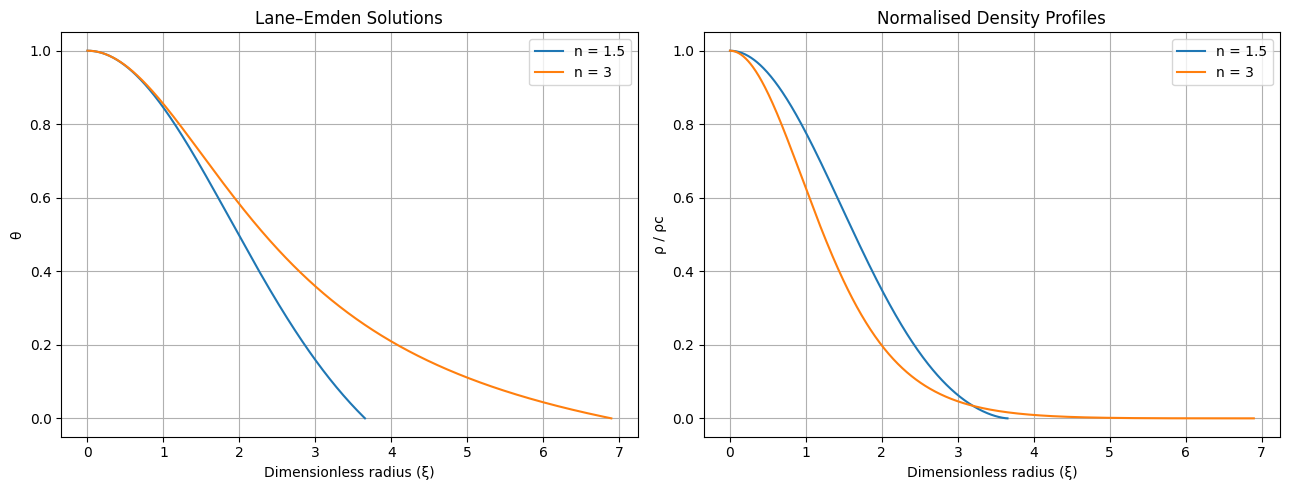

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for n, data in results.items():

    axes[0].plot(
        data["xi"],
        data["theta"],
        label=f"n = {n}"
    )

    axes[1].plot(
        data["xi"],
        data["density"],
        label=f"n = {n}"
    )

axes[0].set_title("Lane–Emden Solutions")
axes[0].set_xlabel("Dimensionless radius (ξ)")
axes[0].set_ylabel("θ")
axes[0].legend()
axes[0].grid()

axes[1].set_title("Normalised Density Profiles")
axes[1].set_xlabel("Dimensionless radius (ξ)")
axes[1].set_ylabel("ρ / ρc")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

# Numerical Results

In [ ]:
print("POLYTROPIC MODEL RESULTS")
print("=" * 65)

for n, data in results.items():

    print(f"\nPolytropic index: n = {n}")
    print(f"Surface radius: {data['surface']:.8f}")
    print(f"Dimensionless mass: {data['mass']:.8f}")
    print(f"Central-to-mean density ratio: {data['concentration']:.6f}")

POLYTROPIC MODEL RESULTS

Polytropic index: n = 1.5
Surface radius: 3.65376008
Dimensionless mass: 2.71406903
Central-to-mean density ratio: 5.990705

Polytropic index: n = 3
Surface radius: 6.89685180
Dimensionless mass: 2.01823874
Central-to-mean density ratio: 54.182481


# Validation against reference values

In [ ]:
reference_values = {
    1.5: {"surface": 3.65375, "mass": 2.71406},
    3: {"surface": 6.89685, "mass": 2.01824}
}

print("NUMERICAL VALIDATION")
print("=" * 65)

for n, data in results.items():

    ref = reference_values[n]

    print(f"\nn = {n}")
    print(
        f"Surface radius error: "
        f"{abs(data['surface'] - ref['surface']):.8f}"
    )
    print(
        f"Mass coefficient error: "
        f"{abs(data['mass'] - ref['mass']):.8f}"
    )

NUMERICAL VALIDATION

n = 1.5
Surface radius error: 0.00001008
Mass coefficient error: 0.00000903

n = 3
Surface radius error: 0.00000180
Mass coefficient error: 0.00000126


# Convergence test

In [ ]:
step_sizes = [0.01, 0.005, 0.001]

for n in polytropic_indices:

    print(f"\nConvergence test: n = {n}")
    print("-" * 55)

    for step in step_sizes:

        _, _, _, surface, mass = solve_lane_emden(n, step)

        print(
            f"h = {step:<8} "
            f"Surface = {surface:.8f}   "
            f"Mass = {mass:.8f}"
        )


Convergence test: n = 1.5
-------------------------------------------------------
h = 0.01     Surface = 3.65376008   Mass = 2.71406903
h = 0.005    Surface = 3.65375508   Mass = 2.71405801
h = 0.001    Surface = 3.65375380   Mass = 2.71405526

Convergence test: n = 3
-------------------------------------------------------
h = 0.01     Surface = 6.89685180   Mass = 2.01823874
h = 0.005    Surface = 6.89684944   Mass = 2.01823667
h = 0.001    Surface = 6.89684865   Mass = 2.01823597


# Analytical validation for n=1

In [ ]:
xi, theta, u, xi_surface, omega = solve_lane_emden(1, 0.001)

# Analytical reference values
xi_exact = np.pi
omega_exact = np.pi

print("ANALYTICAL VALIDATION: n = 1")
print("-" * 45)

print(f"Numerical surface radius: {xi_surface:.8f}")
print(f"Analytical surface radius: {xi_exact:.8f}")

print(f"\nNumerical mass coefficient: {omega:.8f}")
print(f"Analytical mass coefficient: {omega_exact:.8f}")

print(f"\nSurface radius error: {abs(xi_surface - xi_exact):.8e}")
print(f"Mass coefficient error: {abs(omega - omega_exact):.8e}")

ANALYTICAL VALIDATION: n = 1
---------------------------------------------
Numerical surface radius: 3.14159273
Analytical surface radius: 3.14159265

Numerical mass coefficient: 3.14159264
Analytical mass coefficient: 3.14159265

Surface radius error: 7.95595114e-08
Mass coefficient error: 1.54834154e-08


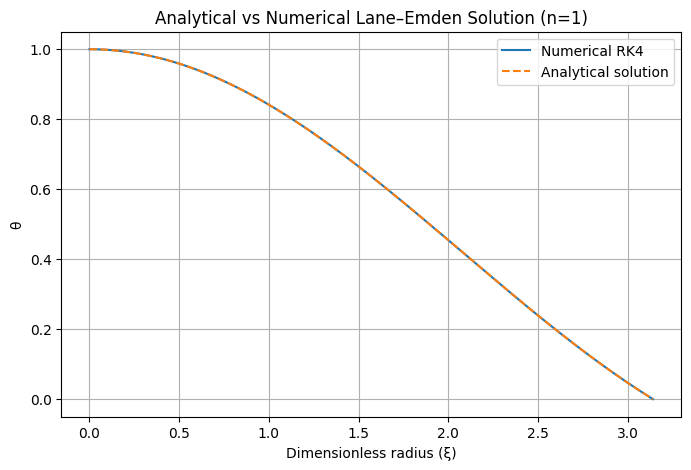

In [ ]:

# Analytical solution
theta_exact = np.sin(xi) / xi

plt.figure(figsize=(8, 5))

plt.plot(xi, theta, label="Numerical RK4")
plt.plot(xi, theta_exact, "--", label="Analytical solution")

plt.xlabel("Dimensionless radius (ξ)")
plt.ylabel("θ")
plt.title("Analytical vs Numerical Lane–Emden Solution (n=1)")
plt.legend()
plt.grid()
plt.show()


In [ ]:
theta_exact = np.sin(xi) / xi

absolute_error = np.abs(theta - theta_exact)

print("Maximum absolute error:", np.max(absolute_error))

Maximum absolute error: 2.5324578345690072e-08


 # Parameter Exploration

In [ ]:
polytropic_indices = [0.5, 1, 1.5, 2, 2.5, 3]

parameter_results = {}

for n in polytropic_indices:

    xi, theta, u, xi_surface, omega = solve_lane_emden(n, h=0.001)

    concentration = xi_surface**3 / (3 * omega)

    parameter_results[n] = {
        "xi_surface": xi_surface,
        "omega": omega,
        "concentration": concentration
    }

    print(
        f"n = {n:<3} | "
        f"xi1 = {xi_surface:.6f} | "
        f"omega = {omega:.6f} | "
        f"Central/Mean Density = {concentration:.4f}"
    )

n = 0.5 | xi1 = 2.752698 | omega = 3.788633 | Central/Mean Density = 1.8352
n = 1   | xi1 = 3.141593 | omega = 3.141593 | Central/Mean Density = 3.2899
n = 1.5 | xi1 = 3.653754 | omega = 2.714055 | Central/Mean Density = 5.9907
n = 2   | xi1 = 4.352875 | omega = 2.411046 | Central/Mean Density = 11.4025
n = 2.5 | xi1 = 5.355275 | omega = 2.187200 | Central/Mean Density = 23.4065
n = 3   | xi1 = 6.896849 | omega = 2.018236 | Central/Mean Density = 54.1825


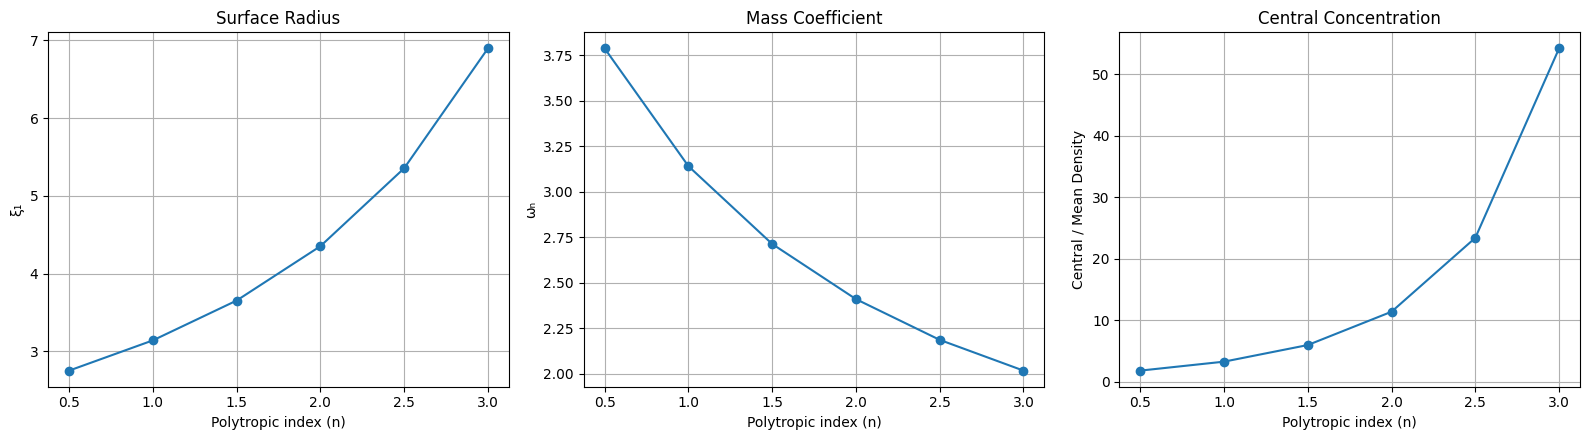

In [ ]:
n_values = list(parameter_results.keys())

xi_values = [parameter_results[n]["xi_surface"] for n in n_values]
omega_values = [parameter_results[n]["omega"] for n in n_values]
concentration_values = [
    parameter_results[n]["concentration"] for n in n_values
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(n_values, xi_values, marker="o")
axes[0].set_title("Surface Radius")
axes[0].set_xlabel("Polytropic index (n)")
axes[0].set_ylabel("ξ₁")

axes[1].plot(n_values, omega_values, marker="o")
axes[1].set_title("Mass Coefficient")
axes[1].set_xlabel("Polytropic index (n)")
axes[1].set_ylabel("ωₙ")

axes[2].plot(n_values, concentration_values, marker="o")
axes[2].set_title("Central Concentration")
axes[2].set_xlabel("Polytropic index (n)")
axes[2].set_ylabel("Central / Mean Density")

for ax in axes:
    ax.grid()

plt.tight_layout()
plt.show()

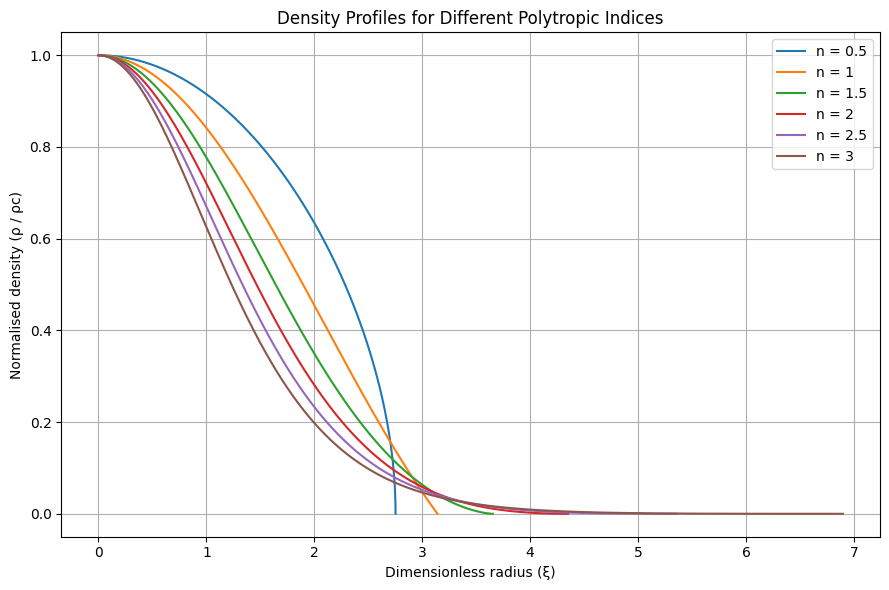

In [ ]:
plt.figure(figsize=(9, 6))

for n in polytropic_indices:

    xi, theta, u, xi_surface, omega = solve_lane_emden(n, h=0.001)

    density = np.maximum(theta, 0)**n

    plt.plot(xi, density, label=f"n = {n}")

plt.xlabel("Dimensionless radius (ξ)")
plt.ylabel("Normalised density (ρ / ρc)")
plt.title("Density Profiles for Different Polytropic Indices")

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
initial = parameter_results[0.5]["concentration"]
final = parameter_results[3]["concentration"]

percentage_increase = ((final - initial) / initial) * 100

print(f"Increase in central concentration: {percentage_increase:.2f}%")

Increase in central concentration: 2852.48%


# Scientific finding

In [ ]:
# SCIENTIFIC INTERPRETATION

n_values = list(parameter_results.keys())

xi_values = [parameter_results[n]["xi_surface"] for n in n_values]
omega_values = [parameter_results[n]["omega"] for n in n_values]
concentration_values = [
    parameter_results[n]["concentration"] for n in n_values
]

concentration_factor = final / initial

print("SCIENTIFIC FINDINGS")
print("-" * 50)

print(
    f"Surface radius increases from {xi_values[0]:.4f} "
    f"to {xi_values[-1]:.4f}."
)

print(
    f"Mass coefficient decreases from {omega_values[0]:.4f} "
    f"to {omega_values[-1]:.4f}."
)

print(
    f"Central-to-mean density ratio increases "
    f"from {initial:.4f} to {final:.4f}."
)

print(
    f"\nPercentage increase in central concentration: "
    f"{percentage_increase:.2f}%"
)

print(
    f"Concentration increases by a factor of "
    f"{concentration_factor:.2f}."
)

SCIENTIFIC FINDINGS
--------------------------------------------------
Surface radius increases from 2.7527 to 6.8968.
Mass coefficient decreases from 3.7886 to 2.0182.
Central-to-mean density ratio increases from 1.8352 to 54.1825.

Percentage increase in central concentration: 2852.48%
Concentration increases by a factor of 29.52.


# Enclosed Mass Fractions

In [ ]:
mass_results = {}

for n in [1.5, 3]:

    xi, theta, u, xi_surface, omega = solve_lane_emden(n, h=0.001)

    enclosed_mass = -(xi**2) * u

    mass_fraction = enclosed_mass / omega

    mass_results[n] = {
        "xi": xi,
        "mass_fraction": mass_fraction
    }

    print(
        f"n = {n} | "
        f"Final enclosed mass fraction = {mass_fraction[-1]:.8f}"
    )

n = 1.5 | Final enclosed mass fraction = 1.00000000
n = 3 | Final enclosed mass fraction = 1.00000000


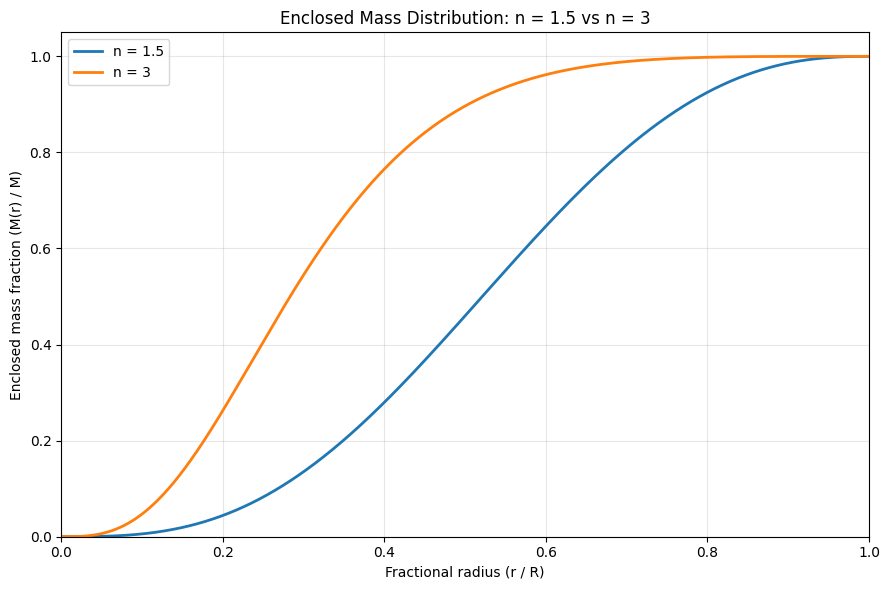

In [ ]:
plt.figure(figsize=(9, 6))

for n, data in mass_results.items():

    fractional_radius = data["xi"] / data["xi"][-1]

    plt.plot(
        fractional_radius,
        data["mass_fraction"],
        linewidth=2,
        label=f"n = {n}"
    )

plt.xlabel("Fractional radius (r / R)")
plt.ylabel("Enclosed mass fraction (M(r) / M)")
plt.title("Enclosed Mass Distribution: n = 1.5 vs n = 3")

plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
for n, data in mass_results.items():

    fractional_radius = data["xi"] / data["xi"][-1]

    mass_at_half_radius = np.interp(
        0.5,
        fractional_radius,
        data["mass_fraction"]
    )

    print(
        f"n = {n}: "
        f"{mass_at_half_radius * 100:.2f}% of mass "
        f"within inner 50% of radius"
    )

n = 1.5: 46.00% of mass within inner 50% of radius
n = 3: 89.67% of mass within inner 50% of radius


# Investigating the critical polytropic index n

In [ ]:
xi, theta, u, xi_surface, omega = solve_lane_emden(
    5, h=0.001, max_xi=20
)

print("Surface radius:", xi_surface)
print("Mass coefficient:", omega)
print("Final theta:", theta[-1])

Surface radius: None
Mass coefficient: None
Final theta: 0.086279596281481


In [ ]:
theta_exact = 1 / np.sqrt(1 + xi**2 / 3)

max_error = np.max(np.abs(theta - theta_exact))

print("Maximum absolute error:", max_error)

Maximum absolute error: 4.9182879990894435e-14


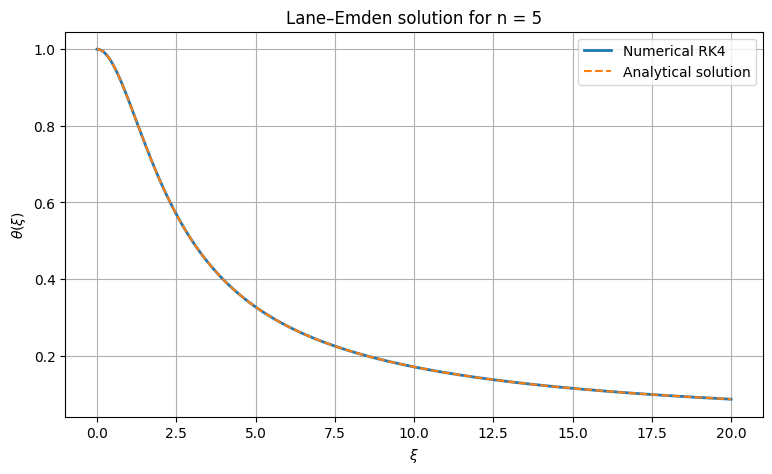

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(xi, theta, label="Numerical RK4", linewidth=2)
plt.plot(xi, theta_exact, "--", label="Analytical solution")

plt.xlabel(r"$\xi$")
plt.ylabel(r"$\theta(\xi)$")
plt.title("Lane–Emden solution for n = 5")
plt.legend()
plt.grid()
plt.show()

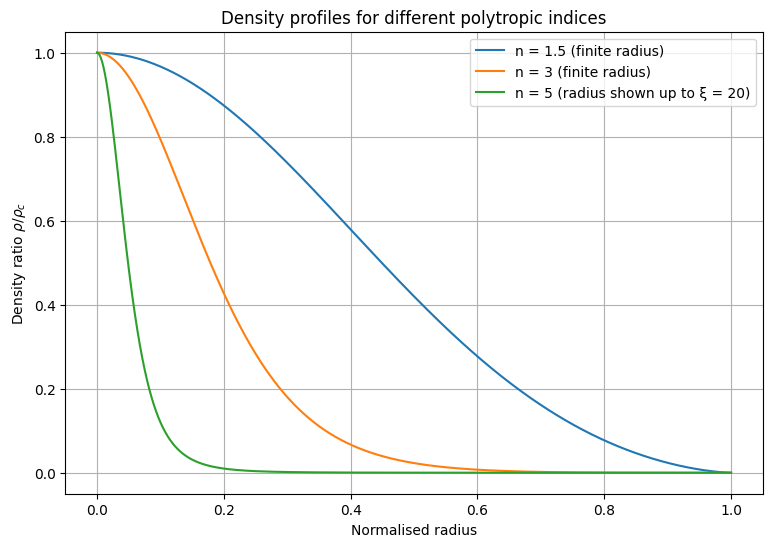

In [ ]:
plt.figure(figsize=(9, 6))

n_values = [1.5, 3, 5]

for n in n_values:
    xi, theta, u, xi_surface, omega = solve_lane_emden(
        n, h=0.001, max_xi=20
    )

    density = np.maximum(theta, 0)**n

    if n == 5:
        label = "n = 5 (no finite surface)"
    else:
        label = f"n = {n}"

    plt.plot(xi, density, label=label)

plt.xlabel("Dimensionless radius (ξ)")
plt.ylabel("Normalised density (ρ/ρc)")
plt.title("Density Profiles for Different Polytropic Indices")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
for limit in [5, 10, 20, 50, 100]:

    xi, theta, u, _, _ = solve_lane_emden(
        5, h=0.001, max_xi=limit
    )

    mass = -(xi**2) * u

    print(
        f"xi = {limit:3} | "
        f"Mass = {mass[-1]:.8f} | "
        f"Error = {abs(mass[-1] - np.sqrt(3)):.8f}"
    )


xi =   5 | Mass = 1.46128051 | Error = 0.27077029
xi =  10 | Mass = 1.65693240 | Error = 0.07511841
xi =  20 | Mass = 1.71274633 | Error = 0.01930448
xi =  50 | Mass = 1.72893779 | Error = 0.00311302
xi = 100 | Mass = 1.73127168 | Error = 0.00077913
